# Children and neighbourhood status in Vienna: data construction and EDA

**What this notebook does.** It builds the *demand* side (children aged 0–5 per 250 m cell) and the *neighbourhood status* variables that `accessibility_analysis.ipynb` regresses access on, and shows what each looks like. All accessibility measures (travel times, 2SFCA, reliability) are built in the analysis notebook, not here.

**Structure**
1. Setup
2. Loading data
3. Constructing the variables: spatial links, children, the four status measures, controls
4. How the variables relate: correlations and status terciles
5. Save

**Output** (read by `accessibility_analysis.ipynb`): `Data/socioeconomic/processed/grid250_analysis.gpkg`, with one row per 250 m routing cell. Figures go to `outputs/eda_socioeconomic/`.

**The variables in the model**

| Role | Variable | Native level | Source |
|---|---|---|---|
| Weight / demand | `children_u6`: children aged 0–5 | Zählsprengel → 100 m → 250 m cell | Statistik Austria, 1 Jan 2026 |
| Status 1 | `pct_tertiary`: % of 25–64 with a degree | district (23) | MA 23, 2023 |
| Status 2 | `net_income_eur`: average net income | district (23) | MA 23, 2023 |
| Status 3 | `share_knowledge_JKM`: % of employed in ICT, finance, professional services | Zählsprengel (1,368) | Statistik Austria, Oct 2024 |
| Status 4 | `rent_eur_m2_std`: asking rent per m², standard flat | Zählsprengel centre | willhaben scrape, 16 Nov 2026 (`rent_measure_reference.md`) |
| Control | `log_child_density` (built in the analysis notebook from `children_u6`) | cell | — |
| Control | `share_foreign_born_15_64` | Zählbezirk (250) | MA 23, 1 Jan 2026 |
| Control | `emp_rate_15_64`: employed per 100 residents 15–64 | Zählsprengel | Statistik Austria |
| Control | `gemeindebau_per_100_res`: municipal-housing dwellings per 100 residents | Zählbezirk | Wiener Wohnen (OGD) |

Only free open data are used. Pennerstorfer & Pennerstorfer had education and country of birth per 250 m cell (paid Statistik Austria data); our finest free levels are listed above.

**Processing pipeline.** Some steps run before this notebook, in scripts (`Data/socioeconomic/scripts/`, run with `python -I` from `Data/socioeconomic`). Everything else happens here, in the order of the sections.

| Stage | Where | In → out |
|---|---|---|
| Extract Vienna from Statistik Austria's national INSPIRE files | `parse_inspire.py` | zipped GML (0.15–0.8 GB) → `raw/statistik_inspire/vienna_extracts/*.csv` (long format: unit, dimension, value, status) |
| Scrape rental adverts | `scrape_willhaben.py` | willhaben search pages → `raw/willhaben_rents_2026-11-16.csv` |
| Clean adverts, build rent index | `build_rent_index.py` | raw adverts → `processed/willhaben_listings_clean.gpkg`, `processed/zsp_rent_index.csv`, `processed/rent_index_cleaning_log.csv` |
| Load and clean every source | this notebook §2 | raw files → in-memory tables; all cleaning rules and checks in **§2h** |
| Link units, build variables | this notebook §3 | → one row per 250 m cell |
| Check coverage, save | this notebook §5 | → `processed/grid250_analysis.gpkg`, `zaehlbezirke_analysis.gpkg/.csv`, `data_dictionary.csv` |
| Routing grid and travel times | `routing.ipynb` (runs first) | → `outputs/routing_origins.csv`, travel-time matrices |
| Access measures, models | `accessibility_analysis.ipynb` | reads `grid250_analysis.gpkg` |

## 1. Setup

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap, BoundaryNorm
from shapely.geometry import box

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*keep_geom_type.*")   # overlay() drops zero-area slivers; harmless
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

_candidates = [Path.cwd(), *Path.cwd().parents]
_candidates += [p / "'My' Code" for p in _candidates.copy()]
NOTEBOOK_DIR = next(p for p in _candidates if (p / "Data" / "KINDERGARTENOGD.json").exists())
DATA = NOTEBOOK_DIR / "Data"
RAW = DATA / "socioeconomic" / "raw"
PROC = DATA / "socioeconomic" / "processed"
INSPIRE = RAW / "statistik_inspire" / "vienna_extracts"
OUT = NOTEBOOK_DIR / "outputs"
FIG = OUT / "eda_socioeconomic"
PROC.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)

GRID_CRS = "EPSG:3035"      # ETRS89-LAEA: the grid's own equal-area CRS, metres
CELL_KM2 = 0.0625           # one 250 m cell

# Colours (validated reference palette): one blue ramp for every magnitude, light = low
BLUE_STEPS = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
BLUE = LinearSegmentedColormap.from_list("blue", BLUE_STEPS)
TERCILE_COLOURS = {"low": "#9ec5f4", "middle": "#3987e5", "high": "#104281"}
CAT = {"blue": "#2a78d6", "orange": "#eb6834", "grey": "#a3a29c"}
INK, INK2, MISSING = "#0b0b0b", "#52514e", "#ebeae6"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 9, "axes.edgecolor": INK2,
                     "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.spines.top": False, "axes.spines.right": False})
print("project folder:", NOTEBOOK_DIR.name)

project folder: 'My' Code


### Helpers
* `read_wien_csv`: the city statistics office (MA 23) uses one CSV layout for all tables: line 1 is a title, `;` separates fields, and numbers are German-style (`1.234,5`). Codes follow `9BBZZ` (BB district, ZZ Zählbezirk; `ZZ = 00` is a district total).
* `wz`, `wquantile`, `wtercile`: child-weighted z-scores, quantiles and terciles, defined exactly as in the analysis notebook.
* `vmap`, `whist`: one map style and one histogram style for every variable.

In [2]:
def read_wien_csv(name):
    """Read an MA 23 open-data CSV into numeric columns."""
    for enc in ("utf-8-sig", "latin-1"):
        try:
            df = pd.read_csv(RAW / name, sep=";", skiprows=1, encoding=enc, dtype=str); break
        except UnicodeDecodeError:
            continue
    df = df.loc[:, ~df.columns.str.startswith("Unnamed")].rename(columns={"SUB_DISCTRICT_CODE": "SUB_DISTRICT_CODE"})
    for col in df.columns:
        if col == "NUTS":
            continue
        s = df[col].str.strip()
        has_comma = s.str.contains(",", na=False)   # comma = decimal, dots = thousands; else a dot + 3 digits = thousands
        s = np.where(has_comma, s.str.replace(".", "", regex=False).str.replace(",", ".", regex=False),
                     s.str.replace(r"\.(?=\d{3}(\D|$))", "", regex=True))
        df[col] = pd.to_numeric(pd.Series(s, index=df.index), errors="coerce")
    return df


def wz(s, w):
    m = np.average(s, weights=w); return (s - m) / np.sqrt(np.average((s - m) ** 2, weights=w))


def wquantile(x, w, q):
    o = np.argsort(x); cw = np.cumsum(w[o]) / w.sum()
    return np.interp(q, cw, x[o])


def wtercile(s, w):
    order = s.sort_values(kind="mergesort").index
    cum = w.loc[order].cumsum() / w.sum()
    return pd.Series(np.select([cum <= 1/3, cum <= 2/3], ["low", "middle"], "high"), index=order).reindex(s.index)


def vmap(ax, gdf, col, title, label="", cmap=BLUE, clip=(2, 98), **kw):
    """Choropleth with the shared style: blue ramp, clipped at the 2nd-98th percentile, district outlines."""
    v = gdf[col].dropna()
    kw.setdefault("vmin", np.percentile(v, clip[0])); kw.setdefault("vmax", np.percentile(v, clip[1]))
    gdf.plot(col, ax=ax, cmap=cmap, legend=True, edgecolor="none", missing_kwds={"color": MISSING},
             legend_kwds={"label": label, "orientation": "horizontal", "shrink": .7, "pad": .02, "aspect": 30}, **kw)
    districts.boundary.plot(ax=ax, color=INK2, lw=.35)
    ax.set_axis_off(); ax.set_title(title, fontsize=10, loc="left", color=INK)


def whist(ax, x, w, title, xlabel, terciles=True, bins=30):
    """Histogram weighted by children, so bars read as '% of children'; dashed lines = child-weighted tercile cuts."""
    m = x.notna() & (w > 0); x, w = x[m].to_numpy(float), w[m].to_numpy(float)
    ax.hist(x, bins=bins, weights=w / w.sum() * 100, color=BLUE_STEPS[3], edgecolor="white", linewidth=.6)
    if terciles:
        for q in wquantile(x, w, [1/3, 2/3]):
            ax.axvline(q, color=INK2, lw=.8, ls="--")
    ax.set(xlabel=xlabel, ylabel="% of children aged 0–5"); ax.set_title(title, fontsize=10, loc="left", color=INK)
    ax.grid(axis="y", color="#e6e5e0", lw=.6); ax.set_axisbelow(True)

## 2. Loading data

| # | Dataset | File | Level | Date |
|---|---|---|---|---|
| 2a | 250 m routing grid (cell codes, ids) | `outputs/routing_origins.csv` (from `routing.ipynb`) | 6,950 cells | — |
| 2b | Zählbezirk boundaries | `raw/ZAEHLBEZIRKOGD.json` | 250 | 2026 |
| 2b | Zählsprengel boundaries | `raw/statistik_zsp_boundaries_2026/` | 1,368 | 2026 |
| 2c | Residents by 5-year age band | `statistik_inspire/…/pd_popreg_zsp_*.csv` | Zählsprengel | 1 Jan 2026 |
| 2c | Employed residents by workplace sector | `statistik_inspire/…/pd_aest_zsp_*.csv` | Zählsprengel | 31 Oct 2024 |
| 2c | Residents per 100 m cell | `statistik_inspire/…/pd_popreg_100m_*.csv` | 100 m | 1 Jan 2026 |
| 2d | Population by age band × birthplace | `raw/zbz_pop_birthcountry_agegroups_since2008.csv` | Zählbezirk | 1 Jan 2026 |
| 2d | Live births by mother's residence | `raw/zbz_births_since2015.csv` | Zählbezirk | 2015–2025 |
| 2e | Education; net income | `raw/bez_education_since2008.csv`, `raw/bez_income_since2011.csv` | district | latest year |
| 2f | Rent index | `processed/zsp_rent_index.csv` (+ listings, for maps) | Zählsprengel | 16 Nov 2026 |
| 2g | Municipal housing estates (*Gemeindebau*) | `raw/GEMBAUTENFLOGD.json` | estate polygons | current |

Each subsection says what is cleaned on loading. §2h collects every rule in one table and checks the data-quality issues against the raw files.

### 2a. The 250 m grid
The cell code gives the geometry: `250mN279825E478325` is the cell whose lower-left corner is at N 2,798,250 m, E 4,783,250 m (EPSG:3035). Row order is kept, because the travel-time matrices are stored in this order.

In [3]:
acc = pd.read_csv(OUT / "routing_origins.csv", usecols=["gid", "cellcode", "origin_id"])     # written by routing.ipynb
ne = acc["cellcode"].str.extract(r"N(\d+)E(\d+)").astype(int) * 10
acc["north"], acc["east"] = ne[0], ne[1]
grid = gpd.GeoDataFrame(acc, geometry=[box(e, n, e + 250, n + 250) for e, n in zip(acc["east"], acc["north"])], crs=GRID_CRS)
print(f"{len(grid):,} cells")

6,950 cells


### 2b. Boundaries

In [4]:
zbz = gpd.read_file(RAW / "ZAEHLBEZIRKOGD.json").to_crs(GRID_CRS)
zbz["SUB_DISTRICT_CODE"] = 90000 + zbz["ZBEZ"].astype(int)      # '0307' -> 90307
zbz["DISTRICT_CODE"] = 90000 + zbz["BEZNR"].astype(int) * 100   # 3 -> 90300
zbz = zbz[["SUB_DISTRICT_CODE", "DISTRICT_CODE", "BEZNR", "geometry"]]
districts = zbz.dissolve("DISTRICT_CODE")[["BEZNR", "geometry"]]

zsp = gpd.read_file(RAW / "statistik_zsp_boundaries_2026" / "zsp_2026_vienna.geojson").to_crs(GRID_CRS)
zsp = zsp.rename(columns={"g_id": "zsp_id"})[["zsp_id", "geometry"]]
print(f"{len(districts)} districts, {len(zbz)} Zählbezirke, {len(zsp):,} Zählsprengel")

23 districts, 250 Zählbezirke, 1,368 Zählsprengel


### 2c. Statistik Austria: Zählsprengel ages and employment, 100 m residents
**Upstream (`parse_inspire.py`):** streams each GML file out of its zip without unpacking, and keeps Vienna only: Zählsprengel codes starting with `9`, or grid cells inside a box around Vienna with a ~2 km margin (EPSG:3035 N 2,780,000–2,826,000, E 4,772,000–4,826,000). Each value is written with its unit, dimension (age band, sex, NACE sector or `TOTAL`) and status flag (`confidential` when Statistik Austria withholds it).

**Here:** long → wide (one row per Zählsprengel, one column per dimension). Withheld values become missing (`NaN`), never zero. Two things to know about these files:
* In the employment file, **`TOTAL` counts all residents**, not workers. Employed persons are the sum of the 21 NACE sectors (§3d).
* The 100 m file covers the box, so it includes cells outside Vienna. Only cells overlapping the routed grid are used (§3b).

In [5]:
def inspire_wide(name):
    d = pd.read_csv(INSPIRE / name, dtype={"unit_id": str})
    d["value"] = pd.to_numeric(d["value"], errors="coerce")
    return d.pivot_table(index="unit_id", columns="dim", values="value", aggfunc="first")

zs = inspire_wide("pd_popreg_zsp_7767c34f.csv")
zs = zs.rename(columns=lambda c: {"TOTAL": "zsp_pop", "male": "zsp_male", "female": "zsp_female"}.get(
    c, "age_" + c.replace("-", "_").replace("+", "plus")))
emp = inspire_wide("pd_aest_zsp_77681182.csv")

h = pd.read_csv(INSPIRE / "pd_popreg_100m_7767c33f.csv")
h["pop100"] = pd.to_numeric(h["value"], errors="coerce").fillna(0)
ne100 = h["unit_id"].str.extract(r"N(\d+)E(\d+)").astype(int)
c100 = gpd.GeoDataFrame(h[["pop100"]], crs=GRID_CRS, geometry=[box(e, n, e + 100, n + 100) for n, e in zip(ne100[0], ne100[1])])
print(f"{len(zs):,} populated Zählsprengel ({zs['zsp_pop'].sum():,.0f} residents); "
      f"{len(c100):,} populated 100 m cells in the extract window (Vienna plus a margin; {c100['pop100'].sum():,.0f} residents)")

1,345 populated Zählsprengel (2,040,914 residents); 41,584 populated 100 m cells in the extract window (Vienna plus a margin; 2,533,041 residents)


### 2d. MA 23: Zählbezirk population by birthplace, and births
**Parsing (`read_wien_csv`):** skip the title line, `;` separator, German number format (`1.234,5`), fix the misspelt `SUB_DISCTRICT_CODE` header. **Selection:** the latest year only (population: 1 Jan 2026; births: 2015–2025, all years kept for the under-3 share). Rows come split by sex (`SEX` 1/2) and are summed. The codes ending in `99` ("Zählbezirk unknown") have no boundary; they hold no residents in 2026 (checked in §2h) and are left out.

In [6]:
popz = read_wien_csv("zbz_pop_birthcountry_agegroups_since2008.csv")
births = read_wien_csv("zbz_births_since2015.csv")
POP_YEAR, BIRTH_LAST = int(popz["REF_YEAR"].max()), int(births["REF_YEAR"].max())
print("population year:", POP_YEAR, "| last birth year:", BIRTH_LAST)

population year: 2026 | last birth year: 2025


### 2e. MA 23: district education and income
* **Education** (`EDU_AKA`): % of residents aged 25–64 whose highest qualification is a **university or academy degree** (`EDU_AKA` = `EDU_UNI` + `EDU_ACA`). Post-secondary colleges (*Kolleg*) are not included. Latest year: 2023.
* **Income** (`AVERAGE_NETINCOME`, `SEX = 0` = both sexes): **mean** annual net income of employees living in the district, from wage-tax data. It includes part-time and part-year workers; the full-time, whole-year variant in the same file is not used. It is a *mean*, not a median. Latest year: 2023.
* Code `90000` (Vienna total) is dropped, leaving 23 districts.

In [7]:
def latest(df, **filters):
    for k, v in filters.items():
        df = df[df[k] == v]
    d = df[df["REF_YEAR"] == df["REF_YEAR"].max()]
    return d.set_index("DISTRICT_CODE"), int(d["REF_YEAR"].max())

edu, edu_year = latest(read_wien_csv("bez_education_since2008.csv"))
inc, inc_year = latest(read_wien_csv("bez_income_since2011.csv"), SEX=0)
print(f"education {edu_year}, income {inc_year}")

education 2023, income 2023


### 2f. Rent index and listings

In [8]:
rent_idx = pd.read_csv(PROC / "zsp_rent_index.csv")
# Listing-level files are scraped adverts and are not redistributed (see README). Only the aggregated
# index above is needed for the analysis; the listing maps in §3e are skipped when these files are absent.
WH_CLEAN, WH_RAW = PROC / "willhaben_listings_clean.gpkg", RAW / "willhaben_rents_2026-11-16.csv"
ONUR_RAW = NOTEBOOK_DIR.parent / "Onur Code" / "Willhaben_rent_prices (1).csv"
LISTINGS = WH_CLEAN.exists() and WH_RAW.exists() and ONUR_RAW.exists()
if LISTINGS:
    wh_clean = gpd.read_file(WH_CLEAN).to_crs(GRID_CRS)
    wh = pd.read_csv(WH_RAW, dtype=str)
    wh_xy = wh["COORDINATES"].str.split(",", expand=True).astype(float)
    wh = gpd.GeoDataFrame(wh, geometry=gpd.points_from_xy(wh_xy[1], wh_xy[0]), crs=4326).to_crs(GRID_CRS)
    onur = pd.read_csv(ONUR_RAW)
    onur = gpd.GeoDataFrame(onur, geometry=gpd.points_from_xy(onur["Longs"], onur["Lats"]), crs=4326).to_crs(GRID_CRS)
print(f"rent index for {rent_idx['rent_eur_m2_std'].notna().sum():,} Zählsprengel"
      + (f"; {len(wh):,} scraped / {len(wh_clean):,} clean listings; Onur's earlier scrape {len(onur):,}" if LISTINGS else "; listing files not present"))

rent index for 1,368 Zählsprengel; 5,347 scraped / 4,071 clean listings; Onur's earlier scrape 3,616


### 2g. Municipal housing estates (*Gemeindebau*)
**The file double-counts large estates.** A big complex is listed once per address (or building phase), and every entry carries the *whole complex's* dwelling count: Hasenleiten appears 27 times with 1,219 dwellings each, the Rasenstadt complex 25 times with 990. Summed as-is, the file claims 302,579 dwellings and puts up to 287 dwellings per 100 residents into some Zählbezirke.

**Fix:** entries are treated as one complex when they report the **same dwelling count** and lie close together: within 1 km for counts of 100 or more (identical large counts nearby are not a coincidence), or within 300 m *and* with the same build year for smaller counts. Each complex is counted once, over the union of its footprints. That leaves about 207,000 dwellings, in line with the roughly 220,000 flats commonly cited for Vienna's municipal housing stock.

In [9]:
from scipy.sparse import lil_matrix
from scipy.sparse.csgraph import connected_components

gb = gpd.read_file(RAW / "GEMBAUTENFLOGD.json").to_crs(GRID_CRS)[["HOFNAME", "WOHNUNGSANZAHL", "BAUJAHR", "geometry"]].reset_index(drop=True)
gb["geometry"] = gb.make_valid()
link = lil_matrix((len(gb), len(gb)))
for n, idx in gb.groupby("WOHNUNGSANZAHL").groups.items():
    idx = list(idx)
    for a_ in range(len(idx)):
        for b_ in range(a_ + 1, len(idx)):
            i, k = idx[a_], idx[b_]
            d = gb.geometry[i].distance(gb.geometry[k])
            if (n >= 100 and d < 1000) or (n < 100 and gb.BAUJAHR[i] == gb.BAUJAHR[k] and d < 300):
                link[i, k] = 1
gb["complex_id"] = connected_components(link, directed=False)[1]
raw_total = gb["WOHNUNGSANZAHL"].sum()
gb = gb.dissolve("complex_id", aggfunc={"HOFNAME": "first", "WOHNUNGSANZAHL": "first", "BAUJAHR": "min"}).reset_index()
print(f"{gb['complex_id'].nunique():,} complexes from {len(link.rows):,} entries; dwellings {raw_total:,.0f} as listed → {gb['WOHNUNGSANZAHL'].sum():,.0f} counted once")

1,652 complexes from 1,776 entries; dwellings 302,579 as listed → 207,288 counted once


### 2h. Cleaning log and data-quality checks
Every cleaning rule, per source. The cell below recomputes the data-quality numbers from the raw files, so the table stays checkable.

| Source | Problem found | Rule applied | Effect |
|---|---|---|---|
| Zählsprengel ages (Statistik Austria) | 5 tiny Zählsprengel have every age and sex value withheld (`confidential`); only their total is published | Withheld → missing, so their children count is 0 | 8 residents in total; no measurable effect |
| Zählsprengel ages | 5-year bands: 0–4, 5–9, … | Children 0–5 = 0–4 band + ⅕ of 5–9 band | Assumes ages are spread evenly within the band |
| Zählsprengel employment | `TOTAL` is all residents, not workers | Employed = sum of the 21 NACE sectors | Avoids halving every share |
| Zählsprengel employment | 5 Zählsprengel withheld; 1 has employment data but no population record | Withheld → missing; employment kept only where a population record exists | Their cells have no knowledge-job share or employment rate and drop out of the models |
| Employment rate | Numerator includes workers over 65; employment (Oct 2024) and ages (Jan 2026) are 14 months apart | Kept; documented as approximate | 6 Zählsprengel exceed 100 |
| Zählsprengel ↔ Zählbezirk | Codes do not nest (Zählsprengel code holds the district, not the Zählbezirk) | Each Zählsprengel assigned to the Zählbezirk with most of its area (§3a) | Median overlap 99.8%; 7 below 90% |
| 100 m residents | File covers a box around Vienna | Only cells overlapping the routed 250 m grid used | — |
| MA 23 tables | German number format, misspelt header, title line | Parsed by `read_wien_csv` | — |
| MA 23 Zählbezirk tables | Codes ending `99` = unknown Zählbezirk, no boundary | Left out | 0 residents in 2026; 4 births in 2020–2025 |
| MA 23 district tables | Row `90000` = Vienna total | Dropped | 23 districts remain |
| MA 23 income | Several income measures; by sex | Mean net income, both sexes (`SEX = 0`) | — |
| Gemeindebau estates | Large complexes listed once per address, each with the whole complex's dwellings | De-duplicated (§2g), then split by footprint (§3g) | 302,579 → 207,288 dwellings |
| Gemeindebau estates | Some invalid polygon geometries | `make_valid()` | — |
| willhaben adverts | Postcode-only locations, typos, duplicates, missing area | Cleaned in `build_rent_index.py`: 5,347 → 4,071 (table below) | See `rent_measure_reference.md` §4.2 |
| Grid cells | 319 edge cells have their centre outside every Zählsprengel / Zählbezirk | Snapped to the nearest Zählbezirk; no Zählsprengel value | 158 children; drop out of the models (§5) |

In [10]:
def raw_long(name):
    d = pd.read_csv(INSPIRE / name, dtype=str)
    return d.assign(value=pd.to_numeric(d["value"], errors="coerce"))

checks = {}
for label, f in [("ages", "pd_popreg_zsp_7767c34f.csv"), ("employment", "pd_aest_zsp_77681182.csv"), ("100 m", "pd_popreg_100m_7767c33f.csv")]:
    d = raw_long(f)
    conf = d[d["status"].eq("confidential")]
    checks[label] = {"values": len(d), "units": d["unit_id"].nunique(), "withheld values": len(conf),
                     "units with withheld values": conf["unit_id"].nunique()}
display(pd.DataFrame(checks).T)

conf_zsp = raw_long("pd_popreg_zsp_7767c34f.csv").query("status == 'confidential'")["unit_id"].unique()
print(f"residents in Zählsprengel with withheld ages: {zs.loc[conf_zsp, 'zsp_pop'].sum():.0f}")
e_long = raw_long("pd_aest_zsp_77681182.csv")
print(f"employment file: TOTAL {e_long.query('dim == "TOTAL"')['value'].sum():,.0f} (all residents) vs "
      f"sum of sectors {e_long.query('dim != "TOTAL"')['value'].sum():,.0f} (employed)")
print(f"Zählsprengel with employment data but no population record: {sorted(set(emp.index) - set(zs.index))}")
unk = popz[(popz["REF_YEAR"] == POP_YEAR) & (popz["SUB_DISTRICT_CODE"] % 100 == 99)]
print(f"residents in 'unknown Zählbezirk' codes (…99), {POP_YEAR}: {(unk['AUT'] + unk['FOR']).sum():,.0f}")
print(f"births with unknown Zählbezirk, {BIRTH_LAST - 5}–{BIRTH_LAST}: "
      f"{births[(births['SUB_DISTRICT_CODE'] % 100 == 99) & (births['REF_YEAR'] >= BIRTH_LAST - 5)]['BIR'].sum():,.0f}")
print(f"education rows: {len(edu)} incl. Vienna total; income rows (both sexes): {len(inc)}")
display(pd.read_csv(PROC / "rent_index_cleaning_log.csv").rename(columns={"n": "listings"}))

,values,units,withheld values,units with withheld values
ages,32280,1345,115,5
employment,29612,1346,105,5
100 m,41584,41584,0,0


residents in Zählsprengel with withheld ages: 8
employment file: TOTAL 2,022,557 (all residents) vs sum of sectors 1,058,946 (employed)
Zählsprengel with employment data but no population record: ['91901032']
residents in 'unknown Zählbezirk' codes (…99), 2026: 0
births with unknown Zählbezirk, 2020–2025: 4
education rows: 24 incl. Vienna total; income rows (both sexes): 24


,step,listings
0,scraped,5347
1,"missing coordinates, rent or area",149
2,location only to postcode centre (LOCATION_QUA...,622
3,area outside 15-300 m2,35
4,"rent outside 5-60 EUR/m2 (typos, parking, totals)",13
5,outside 1st-99th pct of EUR/m2 (9.7-46.6),92
6,"duplicate listing (same place, area, rent)",364
7,outside Vienna's Zählsprengel,1
8,kept,4071


## 3. Constructing the variables

### 3a. Linking the spatial units
* **Cell → Zählbezirk → district:** by the cell's centre point. Edge cells whose centre falls just outside Vienna are snapped to the nearest Zählbezirk.
* **Cell → Zählsprengel:** by centre point. Rates measured per Zählsprengel (knowledge jobs, employment rate, rent) are *assigned* to the cells inside, as Pennerstorfer did.
* **Zählsprengel → Zählbezirk:** the Zählsprengel code does *not* contain the Zählbezirk (its first five digits are the district), so the two boundary sets are overlaid and each Zählsprengel goes to the Zählbezirk holding most of its area.

In [11]:
cent = gpd.GeoDataFrame(grid[["gid"]], geometry=grid.centroid, crs=GRID_CRS)
j = gpd.sjoin(cent, zbz[["SUB_DISTRICT_CODE", "geometry"]], how="left", predicate="within")
j = j[~j.index.duplicated()]
miss = j["SUB_DISTRICT_CODE"].isna()
if miss.any():
    near = gpd.sjoin_nearest(cent[miss], zbz[["SUB_DISTRICT_CODE", "geometry"]], how="left")
    j.loc[miss, "SUB_DISTRICT_CODE"] = near.loc[~near.index.duplicated(), "SUB_DISTRICT_CODE"]
grid["SUB_DISTRICT_CODE"] = j["SUB_DISTRICT_CODE"].astype(int).values
grid["DISTRICT_CODE"] = (grid["SUB_DISTRICT_CODE"] // 100) * 100

jz = gpd.sjoin(cent, zsp[["zsp_id", "geometry"]], how="left", predicate="within")
grid["zsp_id"] = pd.to_numeric(jz[~jz.index.duplicated()]["zsp_id"]).values

ov = gpd.overlay(zsp, zbz[["SUB_DISTRICT_CODE", "geometry"]], how="intersection", keep_geom_type=True)
ov["a"] = ov.area
ov["share"] = ov["a"] / ov.groupby("zsp_id")["a"].transform("sum")
main = ov.sort_values("a", ascending=False).drop_duplicates("zsp_id").set_index("zsp_id")
zsp["SUB_DISTRICT_CODE"] = zsp["zsp_id"].map(main["SUB_DISTRICT_CODE"])
zsp["zbz_overlap_share"] = zsp["zsp_id"].map(main["share"])
zsp = zsp.join(zs, on="zsp_id")
print(f"{miss.sum()} edge cells snapped to the nearest Zählbezirk; {grid['zsp_id'].isna().sum()} cells have no Zählsprengel "
      f"(centre outside every Zählsprengel)")
print(f"Zählsprengel → Zählbezirk: median area share {zsp['zbz_overlap_share'].median():.3f}; "
      f"{(zsp['zbz_overlap_share'] >= 0.99).mean():.0%} at least 99%; {(zsp['zbz_overlap_share'] < 0.9).sum()} below 90%")

319 edge cells snapped to the nearest Zählbezirk; 319 cells have no Zählsprengel (centre outside every Zählsprengel)
Zählsprengel → Zählbezirk: median area share 0.998; 88% at least 99%; 7 below 90%


### 3b. Children aged 0–5 per cell (the demand and the regression weight)
1. **Zählsprengel count:** official 0–4 band + ⅕ of the 5–9 band (assumes 5-year-olds are a fifth of that band).
2. **Zählsprengel → 100 m cells (dasymetric):** each populated 100 m cell belongs to the Zählsprengel containing its centre and gets `children_ZSP × residents_100m / residents_ZSP`. Children are assumed to live where residents of all ages live.
3. **100 m → 250 m (areal weighting):** 100 m cells do not nest in 250 m cells, so each is split by the share of its area in each 250 m cell.
4. **Under-3 / 3–5 split** (for sensitivity checks): each cell gets its Zählbezirk's share of under-3s, estimated from births in the last 3 vs 6 years.

Totals are preserved apart from children whose Zählsprengel lies partly outside the routed grid. *Validation (13 Nov):* the Zählsprengel populations sum exactly to MA 23's Zählbezirk totals, and an independent births-based estimate agrees at Zählbezirk level (r = 0.97); see `data_sources_and_merging_guide.md` §2a.

In [12]:
zsp["children_u6_official"] = zsp["age_0_5"].fillna(0) + zsp["age_5_10"].fillna(0) / 5

ctr = gpd.GeoDataFrame(geometry=c100.centroid, crs=GRID_CRS)
jc = gpd.sjoin(ctr, zsp[["zsp_id", "geometry"]], how="left", predicate="within")
jc = jc[~jc.index.duplicated()]
m100 = jc["zsp_id"].isna()
if m100.any():
    nr = gpd.sjoin_nearest(ctr[m100], zsp[["zsp_id", "geometry"]], how="left")
    jc.loc[m100, "zsp_id"] = nr.loc[~nr.index.duplicated(), "zsp_id"]
c100["zsp_id"] = jc["zsp_id"].values
zsp_res = c100.groupby("zsp_id")["pop100"].transform("sum")
kids_zsp = c100["zsp_id"].map(zsp.set_index("zsp_id")["children_u6_official"]).fillna(0)
c100["kids100"] = np.where(zsp_res > 0, kids_zsp * c100["pop100"] / zsp_res, 0)

piece = gpd.overlay(c100[["pop100", "kids100", "geometry"]], grid[["cellcode", "geometry"]], how="intersection")
frac = piece.area / 10_000
cell_sum = pd.DataFrame({"cellcode": piece["cellcode"], "pop_official": piece["pop100"] * frac,
                         "children_u6": piece["kids100"] * frac}).groupby("cellcode").sum()
grid["pop_official"] = grid["cellcode"].map(cell_sum["pop_official"]).fillna(0)
grid["children_u6"] = grid["cellcode"].map(cell_sum["children_u6"]).fillna(0)

b = births.groupby(["SUB_DISTRICT_CODE", "REF_YEAR"])["BIR"].sum().unstack()
u3_share = (b.loc[:, BIRTH_LAST - 2:BIRTH_LAST].sum(axis=1) / b.loc[:, BIRTH_LAST - 5:BIRTH_LAST].sum(axis=1)).clip(0, 1)
grid["children_u3"] = grid["children_u6"] * grid["SUB_DISTRICT_CODE"].map(u3_share).fillna(0.5)
grid["children_3_5"] = grid["children_u6"] - grid["children_u3"]
grid["child_density_km2"] = grid["children_u6"] / CELL_KM2

print(f"Children 0–5: Vienna {zsp['children_u6_official'].sum():,.0f}; in the routed grid {grid['children_u6'].sum():,.0f} "
      f"(under 3: {grid['children_u3'].sum():,.0f}); cells with < 1 child: {(grid['children_u6'] < 1).mean():.0%}")

Children 0–5: Vienna 113,331; in the routed grid 111,638 (under 3: 55,491); cells with < 1 child: 51%


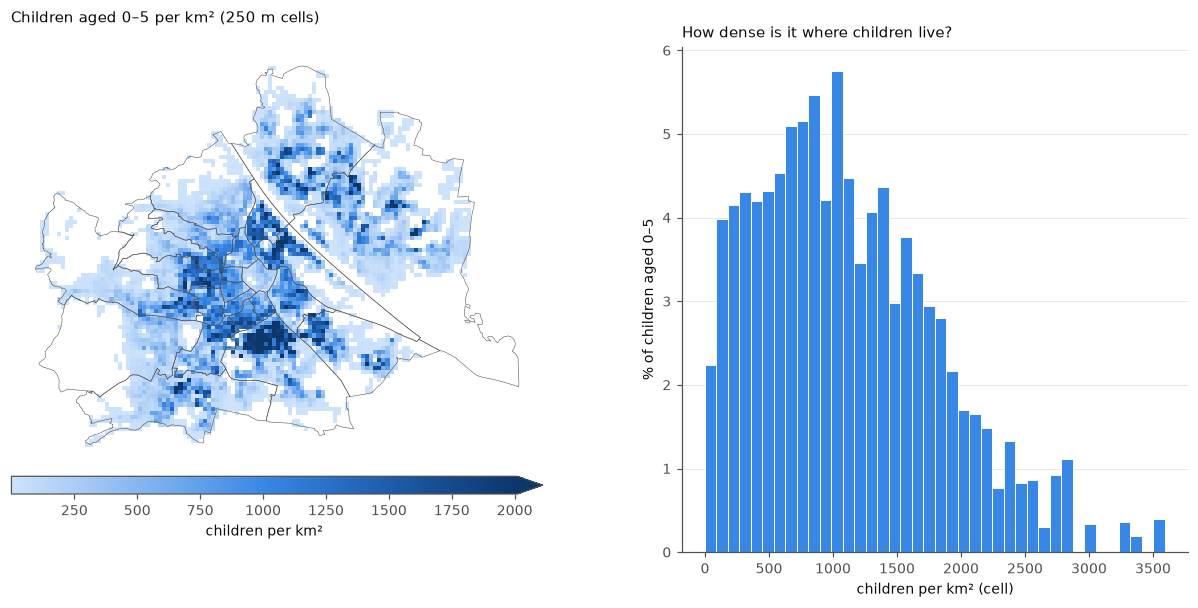

In [13]:
kid = grid["children_u6"] > 0
fig, axes = plt.subplots(1, 2, figsize=(12, 5.6), gridspec_kw={"width_ratios": [1.5, 1]})
vmap(axes[0], grid[kid], "child_density_km2", "Children aged 0–5 per km² (250 m cells)", "children per km²", clip=(0, 98))
whist(axes[1], grid.loc[kid, "child_density_km2"], grid.loc[kid, "children_u6"],
      "How dense is it where children live?", "children per km² (cell)", terciles=False, bins=40)
fig.tight_layout(); fig.savefig(FIG / "01_children.png", bbox_inches="tight"); plt.show()

### 3c. Status measures 1 and 2: education and income (district)
* `pct_tertiary`: % of 25–64-year-olds with a tertiary degree (`EDU_AKA`).
* `net_income_eur`: average annual net income of employees (both sexes).

Every cell takes its district's value. With only **23 values** each, standard errors for these measures are clustered by district.

In [14]:
bez = pd.DataFrame({"pct_tertiary": edu["EDU_AKA"], "net_income_eur": inc["AVERAGE_NETINCOME"]}).drop(index=90000, errors="ignore")
grid = grid.merge(bez, left_on="DISTRICT_CODE", right_index=True, how="left")
districts = districts.join(bez)
bez.assign(district=(bez.index - 90000) // 100).set_index("district").sort_values("pct_tertiary").round(1).T

district,11.0,10.0,21.0,22.0,12.0,23.0,20.0,16.0,15.0,14.0,17.0,5.0,2.0,3.0,19.0,13.0,6.0,4.0,18.0,1.0,9.0,8.0,7.0
pct_tertiary,15.6,17.8,19.7,24.8,25.4,25.6,26.1,28.4,29.8,33.1,35.9,38.2,40.6,43.0,43.2,44.9,49.6,50.8,51.8,53.4,54.2,54.4,55.6
net_income_eur,25300.7,23958.3,27267.1,29785.9,25280.3,30250.1,23642.2,25009.2,23602.0,29664.1,26551.5,25884.2,28183.4,30702.3,33187.8,35462.0,29366.7,31166.5,32234.7,40232.0,30683.6,31036.7,31524.2


### 3d. Status measure 3: knowledge jobs (Zählsprengel)
From Statistik Austria's employment register (residents by sector of their workplace): `share_knowledge_JKM` = employed residents in information & communication (NACE J), finance (K) and professional & scientific services (M) ÷ all employed residents. The file's `TOTAL` column counts all residents, so the denominator is the sum of the sectors. `share_lowwage_IN` (hospitality I, admin & support N) is built alongside for reference.

In [15]:
nace = [c for c in emp.columns if c != "TOTAL"]
zsp["employed"] = zsp["zsp_id"].map(emp[nace].sum(axis=1, min_count=1)).where(zsp["zsp_pop"].notna())   # only Zählsprengel with a population record
zsp["share_knowledge_JKM"] = zsp["zsp_id"].map(emp[["J", "K", "M"]].sum(axis=1)) / zsp["employed"] * 100
zsp["share_lowwage_IN"] = zsp["zsp_id"].map(emp[["I", "N"]].sum(axis=1)) / zsp["employed"] * 100
zsp["zsp_id"] = pd.to_numeric(zsp["zsp_id"])
for c in ["share_knowledge_JKM", "share_lowwage_IN"]:
    grid[c] = grid["zsp_id"].map(zsp.set_index("zsp_id")[c])
print(f"knowledge-job share: median Zählsprengel {zsp['share_knowledge_JKM'].median():.1f}%, "
      f"range {zsp['share_knowledge_JKM'].min():.1f}–{zsp['share_knowledge_JKM'].max():.1f}%")

knowledge-job share: median Zählsprengel 20.5%, range 0.0–59.1%


### 3e. Status measure 4: rent (Zählsprengel centre)
Stands in for Pennerstorfer's proprietary house prices (*"price of a standardised apartment at the centroid of the Zählsprengel"*). Built outside this notebook, in two steps:
1. `scrape_willhaben.py`: 5,347 Vienna rental adverts with willhaben's own coordinates, floor area and flat traits.
2. `build_rent_index.py`: cleaning (4,071 kept) → hedonic model removing size, rooms, floor, outdoor space, new-build and landlord type → Gaussian kernel over the 20 nearest listings at each Zählsprengel's centre → **€ per m² per month for a standard 65 m² flat**.

The full method, a toy example and the comparison with Pennerstorfer and Onur are in `rent_measure_reference.md`. The three maps below show why each step is needed.

In [16]:
grid["rent_eur_m2_std"] = grid["zsp_id"].map(rent_idx.set_index(pd.to_numeric(rent_idx["zsp_id"]))["rent_eur_m2_std"])

**Listing locations.** Left: Onur's earlier scrape, geocoded by Google from the address text. A third of the addresses have no street, so Google put them on their district's centre (orange circles; size = number of listings). Right: the new scrape uses willhaben's own coordinates. Adverts located only to a postcode centre (orange) are dropped for the same reason.

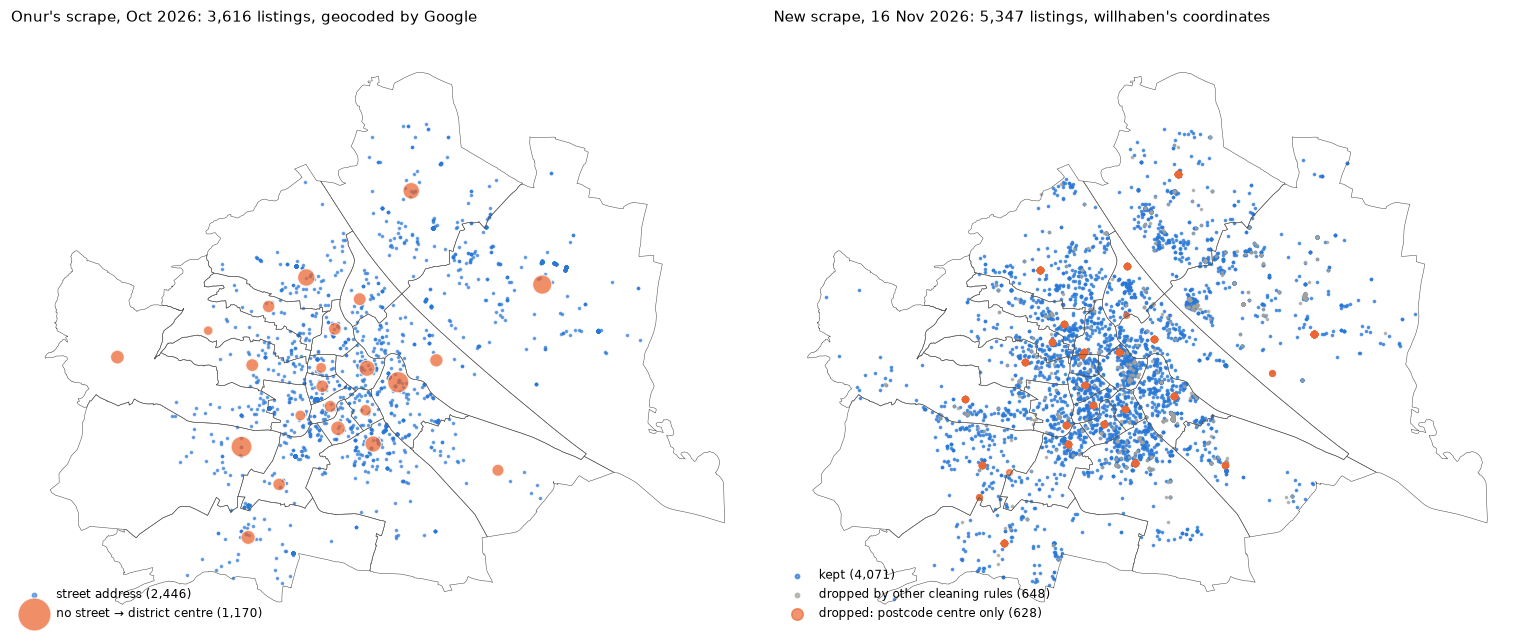

In [17]:
if not LISTINGS:
    print("Listing files not present: skipping this map (the saved figure is outputs/eda_socioeconomic/02a_rent_listing_locations.png).")
else:
    wh["status"] = np.where(wh["ADID"].astype(str).isin(wh_clean["ADID"].astype(str)), "kept",
                    np.where(wh["LOCATION_QUALITY"].astype(float) < 0.75, "postcode", "other"))
    onur["no_street"] = onur["Address"].str.count(",") <= 2           # "1100 Wien, 10. Bezirk, Favoriten"
    stack_n = onur[onur.no_street].geometry.apply(lambda g: (round(g.x, -1), round(g.y, -1))).value_counts()
    stack_pts = gpd.GeoSeries(gpd.points_from_xy([k[0] for k in stack_n.index], [k[1] for k in stack_n.index]), crs=GRID_CRS)

    fig, axes = plt.subplots(1, 2, figsize=(14, 6.4))
    for ax in axes:
        districts.boundary.plot(ax=ax, color=INK2, lw=.35); ax.set_axis_off()
    onur[~onur.no_street].plot(ax=axes[0], color=CAT["blue"], markersize=2, alpha=.6, label=f"street address ({(~onur.no_street).sum():,})")
    stack_pts.plot(ax=axes[0], color=CAT["orange"], markersize=np.sqrt(stack_n.values) * 14, alpha=.75, edgecolor="white", lw=.8,
                   label=f"no street → district centre ({onur.no_street.sum():,})")
    axes[0].set_title(f"Onur's scrape, Oct 2026: {len(onur):,} listings, geocoded by Google", fontsize=10, loc="left")
    for key, lab, col, ms in [("kept", "kept", CAT["blue"], 2), ("other", "dropped by other cleaning rules", CAT["grey"], 2),
                              ("postcode", "dropped: postcode centre only", CAT["orange"], 14)]:
        d = wh[wh.status == key]
        d.plot(ax=axes[1], color=col, markersize=ms, alpha=.7, label=f"{lab} ({len(d):,})")
    axes[1].set_title(f"New scrape, 16 Nov 2026: {len(wh):,} listings, willhaben's coordinates", fontsize=10, loc="left")
    for ax in axes:
        ax.legend(loc="lower left", fontsize=8, frameon=False, markerscale=2)
    fig.tight_layout(); fig.savefig(FIG / "02a_rent_listing_locations.png", bbox_inches="tight"); plt.show()

**Listings per Zählsprengel.** The finest official unit is too thin for a raw average: most Zählsprengel have 0–2 listings. This is why the index borrows from the 20 nearest listings instead.

listings per populated Zählsprengel: median 1; none 30%, 1–4 53%, 5–9 11%, 10+ 6%


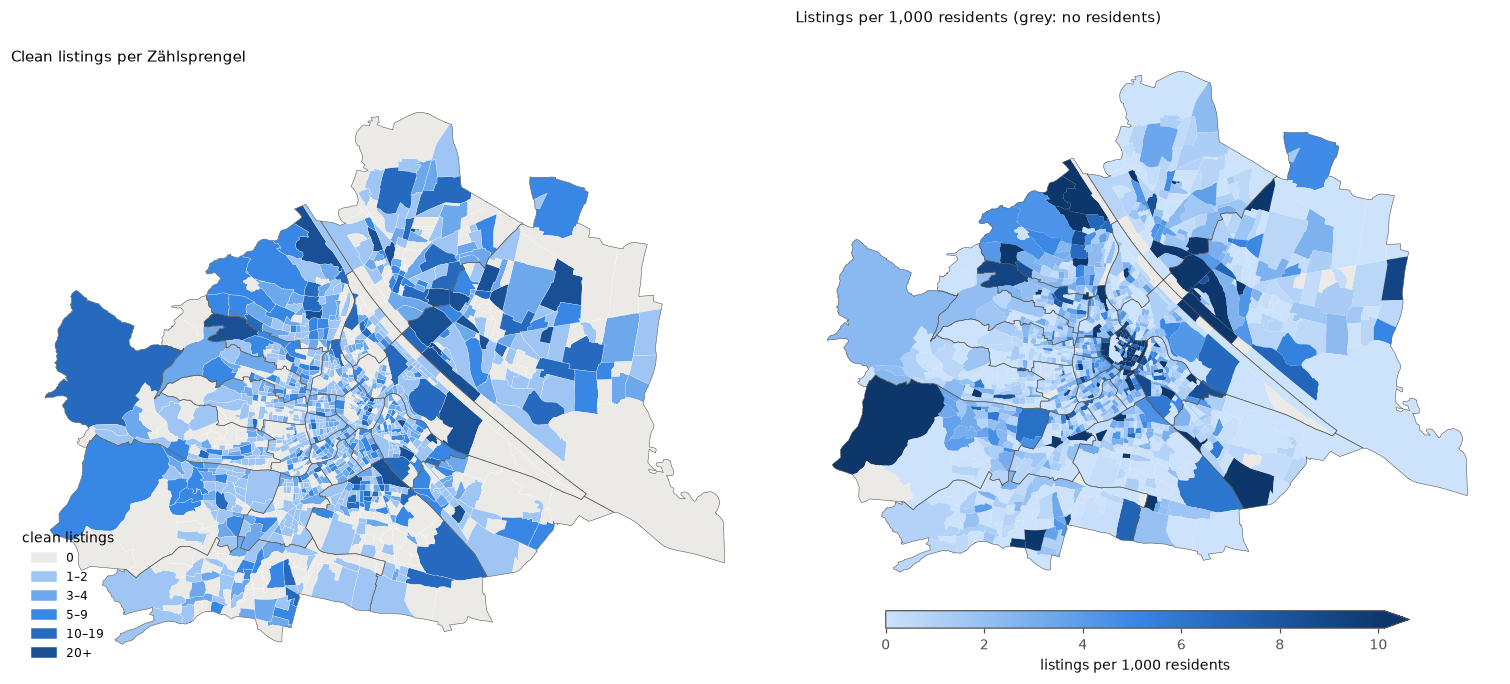

In [18]:
zr = zsp[["zsp_id", "geometry"]].merge(rent_idx.assign(zsp_id=pd.to_numeric(rent_idx["zsp_id"])), on="zsp_id", how="left")
zr["listings_per_1000_res"] = np.where(zr["pop_total"] > 0, zr["rent_n_in_zsp"] / zr["pop_total"] * 1000, np.nan)
zpop_ = zr[zr.pop_total > 0]
print(f"listings per populated Zählsprengel: median {zpop_.rent_n_in_zsp.median():.0f}; none {(zpop_.rent_n_in_zsp == 0).mean():.0%}, "
      f"1–4 {zpop_.rent_n_in_zsp.between(1, 4).mean():.0%}, 5–9 {zpop_.rent_n_in_zsp.between(5, 9).mean():.0%}, "
      f"10+ {(zpop_.rent_n_in_zsp >= 10).mean():.0%}")

cls_cmap = ListedColormap([MISSING] + BLUE_STEPS[1::1][:5])
cls_bins = [0, 1, 3, 5, 10, 20, 1000]
fig, axes = plt.subplots(1, 2, figsize=(14, 6.4))
zr.plot("rent_n_in_zsp", ax=axes[0], cmap=cls_cmap, norm=BoundaryNorm(cls_bins, cls_cmap.N), edgecolor="white", lw=.15)
districts.boundary.plot(ax=axes[0], color=INK2, lw=.35); axes[0].set_axis_off()
axes[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=cls_cmap(i)) for i in range(cls_cmap.N)],
               labels=["0", "1–2", "3–4", "5–9", "10–19", "20+"], title="clean listings", loc="lower left", fontsize=8, frameon=False)
axes[0].set_title("Clean listings per Zählsprengel", fontsize=10, loc="left")
vmap(axes[1], zr, "listings_per_1000_res", "Listings per 1,000 residents (grey: no residents)", "listings per 1,000 residents", clip=(0, 95))
fig.tight_layout(); fig.savefig(FIG / "02b_rent_listing_density_zsp.png", bbox_inches="tight"); plt.show()

**Rent per Zählsprengel.** Left: raw median € per m² where a Zählsprengel has at least 5 listings. Right: the standard-flat index used in the analysis. Both use one colour scale. Raw medians run higher, because they include new-builds, flats with outdoor space and small flats, which the index adjusts away.

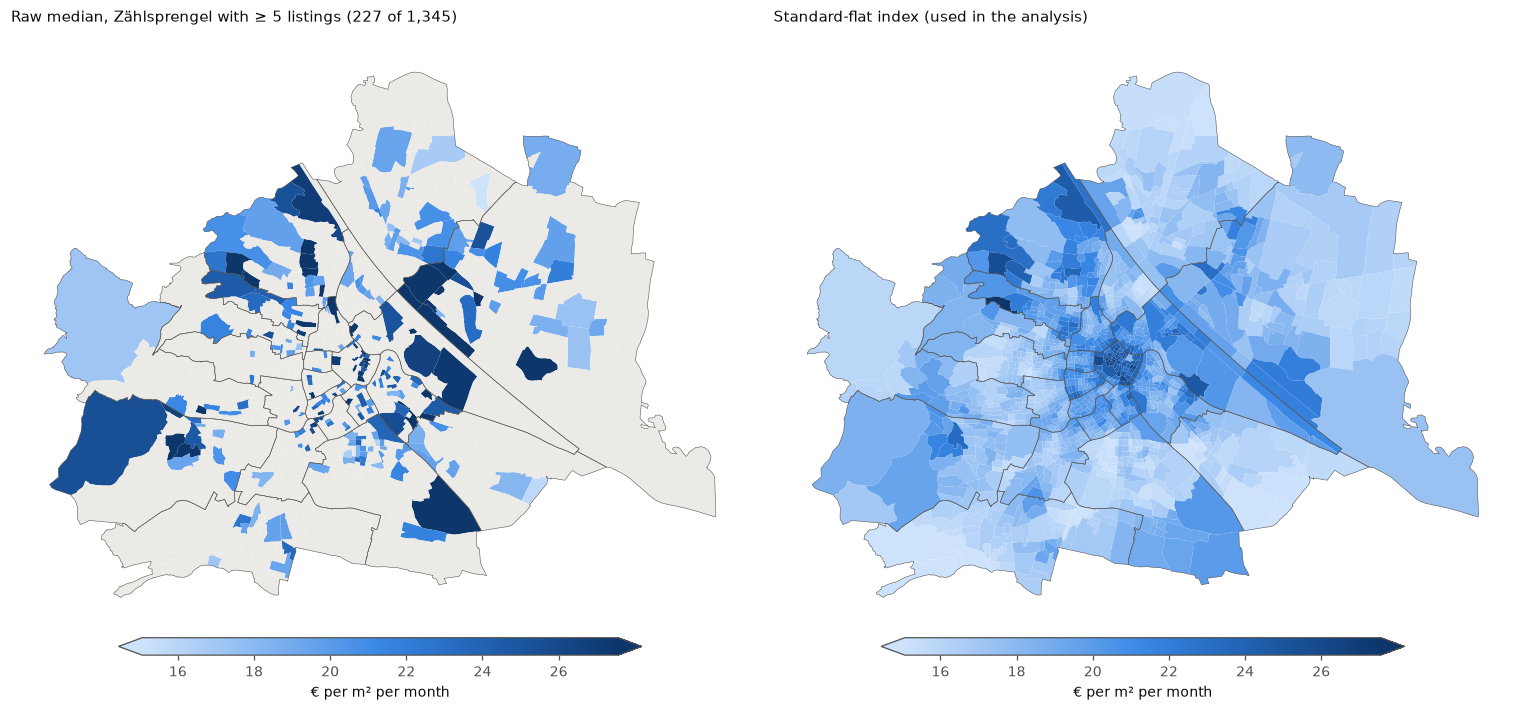

median: raw 21.5 vs index 18.1 € per m²; Spearman raw vs index 0.74


In [19]:
MIN_N = 5
zr["rent_raw_median_shown"] = zr["rent_raw_median_zsp"].where(zr["rent_n_in_zsp"] >= MIN_N)
lo, hi = np.nanpercentile(pd.concat([zr["rent_eur_m2_std"], zr["rent_raw_median_shown"]]).dropna(), [2, 98])
fig, axes = plt.subplots(1, 2, figsize=(14, 6.6))
vmap(axes[0], zr, "rent_raw_median_shown", f"Raw median, Zählsprengel with ≥ {MIN_N} listings ({zr.rent_raw_median_shown.notna().sum()} of {len(zpop_):,})",
     "€ per m² per month", vmin=lo, vmax=hi)
vmap(axes[1], zr, "rent_eur_m2_std", "Standard-flat index (used in the analysis)", "€ per m² per month", vmin=lo, vmax=hi)
fig.tight_layout(); fig.savefig(FIG / "02c_rent_by_zsp.png", bbox_inches="tight"); plt.show()
ok = zr.rent_raw_median_shown.notna()
print(f"median: raw {zr.rent_raw_median_shown.median():.1f} vs index {zr.rent_eur_m2_std.median():.1f} € per m²; "
      f"Spearman raw vs index {zr.loc[ok, ['rent_raw_median_shown', 'rent_eur_m2_std']].corr('spearman').iloc[0, 1]:.2f}")

### 3f. The four status measures side by side
**Top:** each measure mapped at the level it is measured (districts, or Zählsprengel). **Bottom:** its distribution *across children*: cells weighted by children aged 0–5, so a bar is "% of children living where status takes this value". Dashed lines mark the child-weighted **tercile** cuts used in the figures of the analysis. The two district measures show as spikes, one per district.

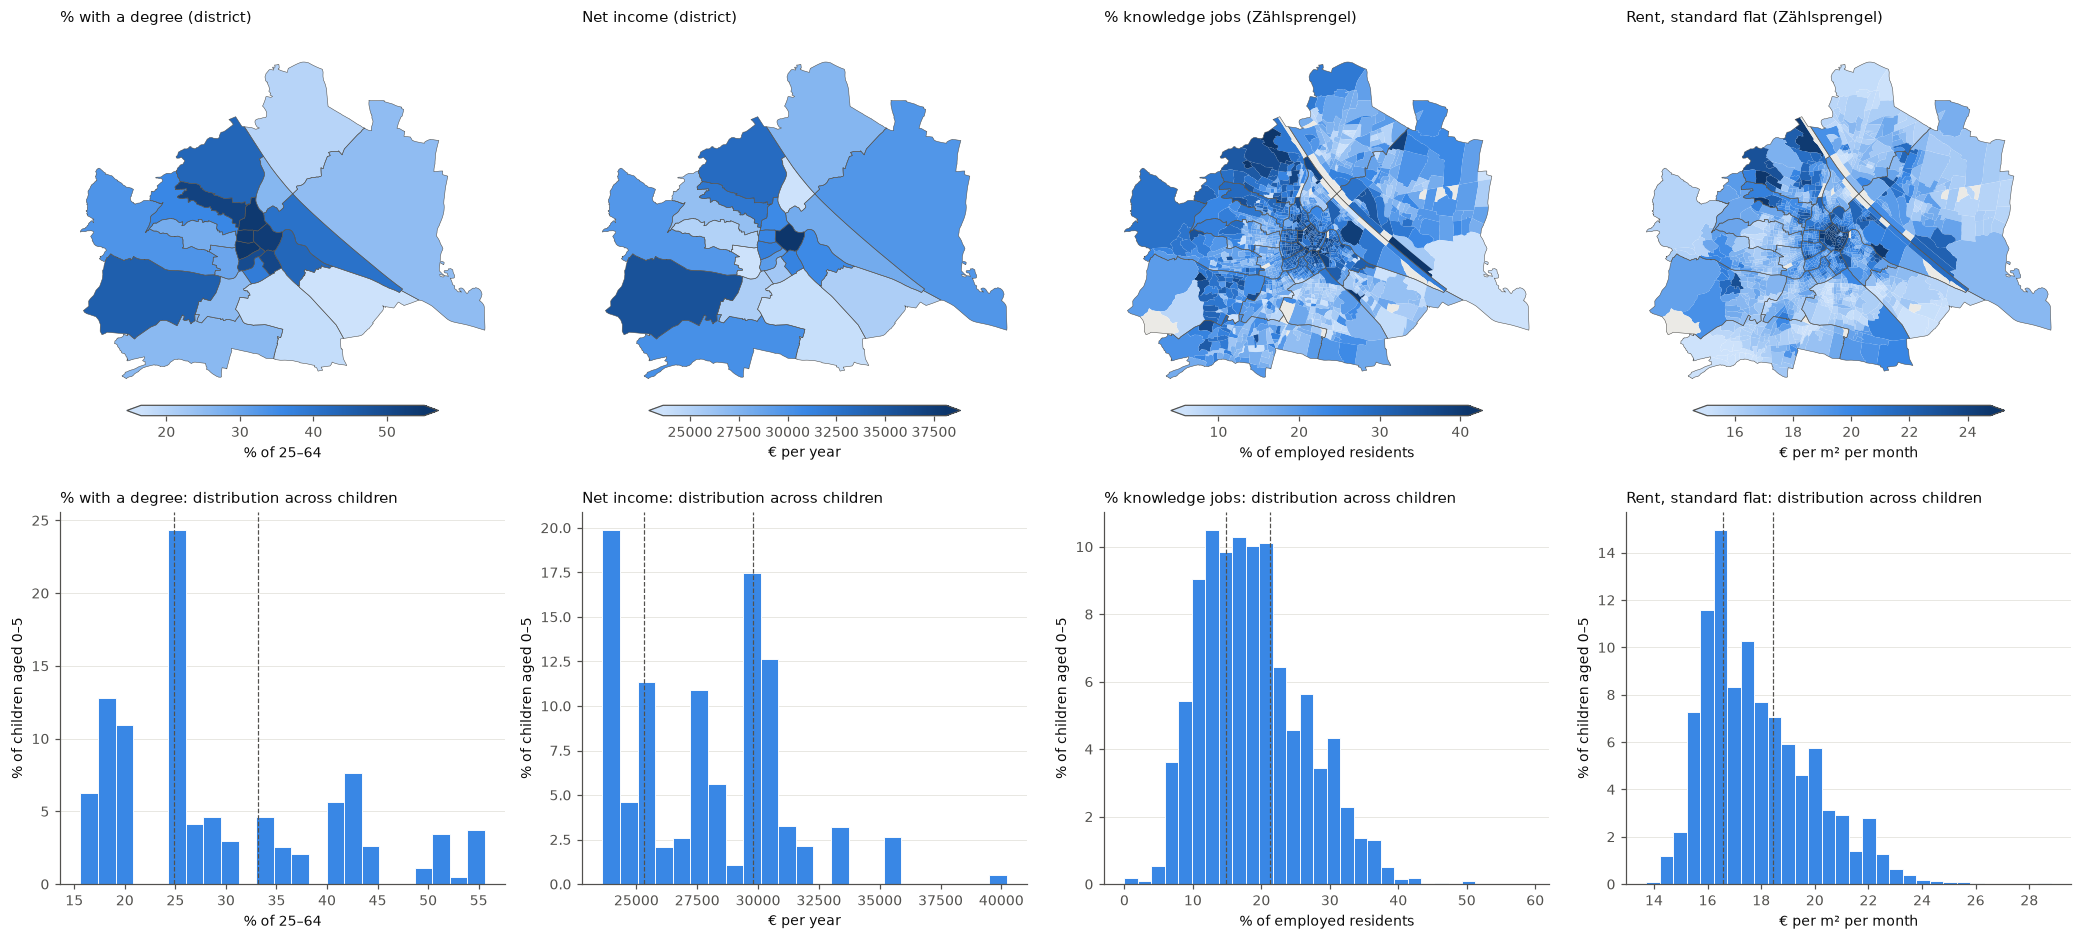

,count,mean,std,min,25%,50%,75%,max
pct_tertiary,4298.0,29.6,10.7,15.6,19.7,25.6,38.2,55.6
net_income_eur,4298.0,28901.9,3252.3,23602.0,26551.5,29664.1,30250.1,40232.0
share_knowledge_JKM,4128.0,20.9,7.9,0.0,15.4,20.5,26.3,59.1
rent_eur_m2_std,4185.0,17.9,2.3,13.7,16.2,17.4,19.1,28.8


In [20]:
SES = {"pct_tertiary": ("% with a degree", "district", "% of 25–64"),
       "net_income_eur": ("Net income", "district", "€ per year"),
       "share_knowledge_JKM": ("% knowledge jobs", "Zählsprengel", "% of employed residents"),
       "rent_eur_m2_std": ("Rent, standard flat", "Zählsprengel", "€ per m² per month")}
zsp_map = zsp.merge(zr[["zsp_id", "rent_eur_m2_std"]], on="zsp_id", how="left")
zsp_map.loc[zsp_map["zsp_pop"].fillna(0) == 0, ["share_knowledge_JKM", "rent_eur_m2_std"]] = np.nan   # no residents: grey
native = {"pct_tertiary": districts, "net_income_eur": districts, "share_knowledge_JKM": zsp_map, "rent_eur_m2_std": zsp_map}

fig, axes = plt.subplots(2, 4, figsize=(19, 9.2), gridspec_kw={"height_ratios": [1.45, 1]})
for k, (col, (lab, lvl, unit)) in enumerate(SES.items()):
    vmap(axes[0, k], native[col], col, f"{lab} ({lvl})", unit)
    whist(axes[1, k], grid.loc[kid, col], grid.loc[kid, "children_u6"], f"{lab}: distribution across children", unit,
          bins=23 if lvl == "district" else 30)
fig.tight_layout(); fig.savefig(FIG / "03_status_measures.png", bbox_inches="tight"); plt.show()
grid.loc[kid, list(SES)].describe().T.round(1)

### 3g. Controls
* `share_foreign_born_15_64` (**Zählbezirk**): % of residents aged 15–64 born abroad, the closest free match to Pennerstorfer's country-of-birth control (they split Austria / EU / non-EU; we only have Austria vs abroad at this level).
* `emp_rate_15_64` (**Zählsprengel**): employed residents ÷ residents aged 15–64 × 100, a stand-in for Pennerstorfer's female employment rate. Approximate: workers over 65 are in the numerator, and the two counts are 14 months apart.
* `gemeindebau_per_100_res` (**Zählbezirk**): municipal-housing dwellings per 100 residents. Duplicates are removed first (2g). Large estates cross Zählbezirk boundaries, so each complex's dwellings are **split by the share of its footprint in each Zählbezirk** (and in each 250 m cell for `gemeindebau_dwellings`). Not in Pennerstorfer's models, but specific to Vienna, with its large municipal housing stock: it captures housing tenure, which shapes who lives where. It is **not** a clean low-income measure, because the income caps for new tenants are high and are not re-checked after moving in. The dwelling count per 250 m cell (`gemeindebau_dwellings`) is saved too.
* `log_child_density` (**cell**): built in the analysis notebook as log(1 + children per km²); its raw form is mapped in 3b.
* `ubahn_in_cell` (**cell**): built in the analysis notebook from GTFS U-Bahn stops.

dwellings kept after the split: 207,288 of 207,288
Gemeindebau dwellings per 100 residents: Zählbezirk median 5.7, max 54.1; 62 Zählbezirke have none


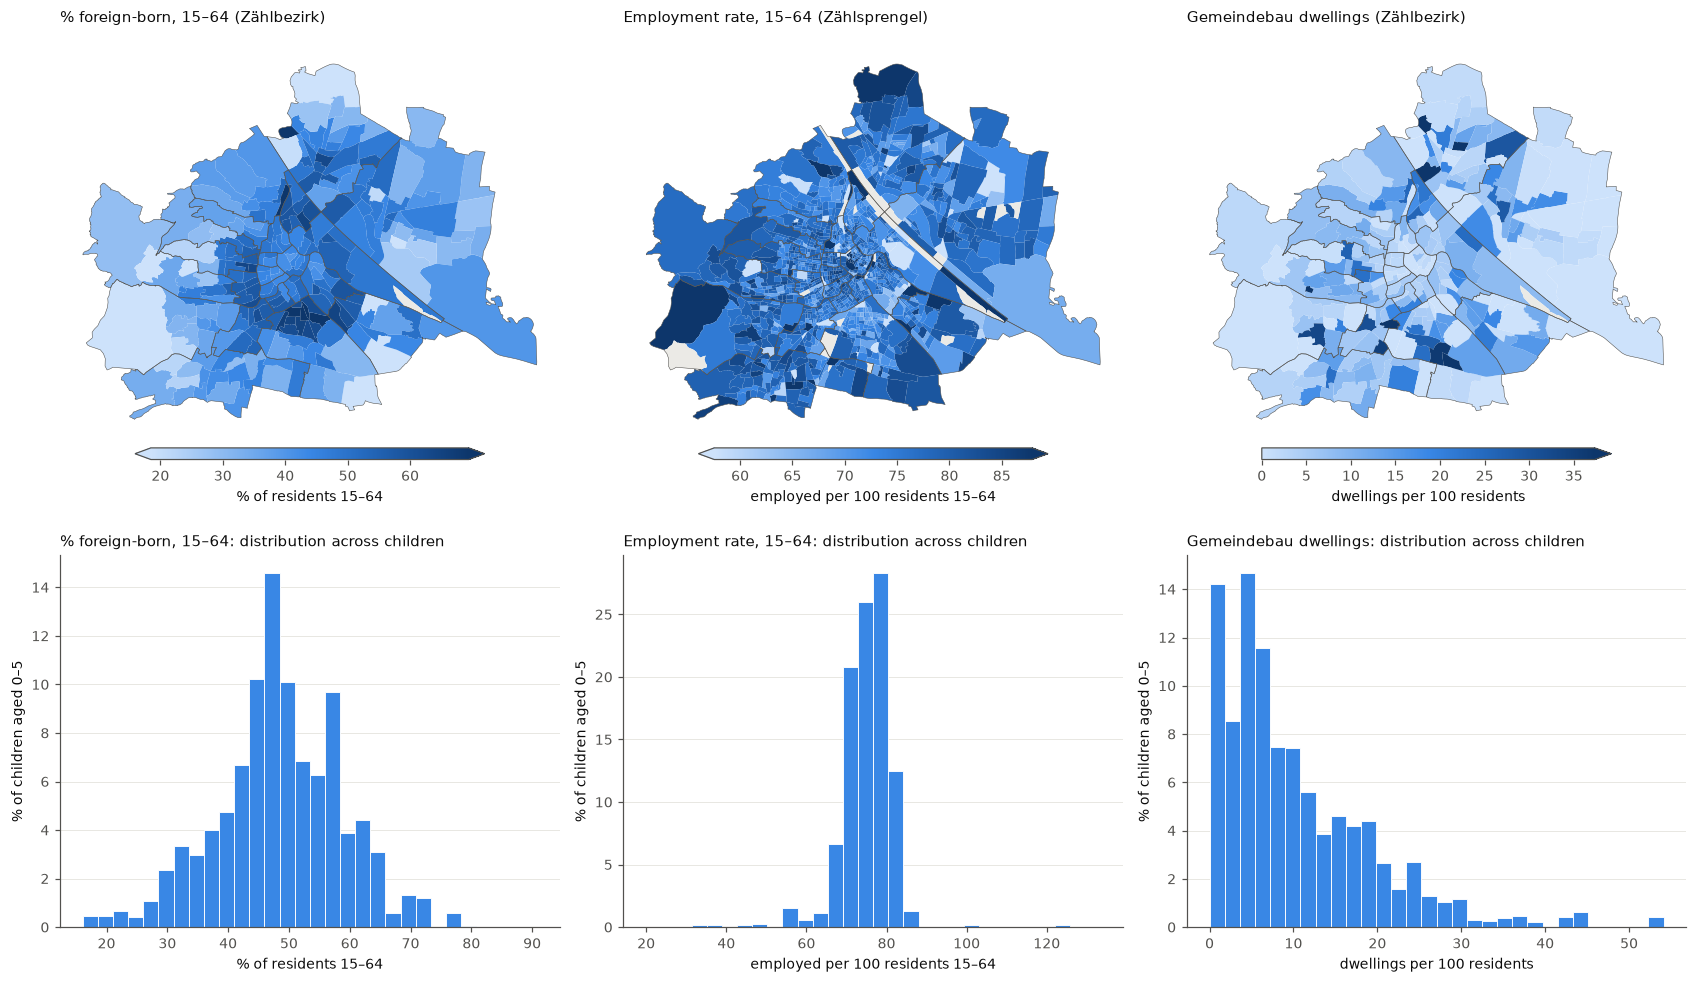

Zählsprengel with an employment rate above 100 (approximation artefacts): 6


In [21]:
d = popz[popz["REF_YEAR"] == POP_YEAR].groupby(["SUB_DISTRICT_CODE", "AGR3"])[["AUT", "FOR"]].sum().unstack()
zbz_ctrl = pd.DataFrame({"share_foreign_born_15_64": d[("FOR", 2)] / (d[("AUT", 2)] + d[("FOR", 2)]) * 100,
                         "pop_total": d.sum(axis=1)})
grid["share_foreign_born_15_64"] = grid["SUB_DISTRICT_CODE"].map(zbz_ctrl["share_foreign_born_15_64"])

pop1564 = zsp[[f"age_{a}_{a + 5}" for a in range(15, 65, 5)]].sum(axis=1, min_count=1)
zsp["emp_rate_15_64"] = zsp["employed"] / pop1564 * 100
grid["emp_rate_15_64"] = grid["zsp_id"].map(zsp.set_index("zsp_id")["emp_rate_15_64"])

def split_by_area(units, key):
    """Dwellings of each estate shared out by the share of its footprint inside each unit."""
    g = gb.assign(eid=range(len(gb)), estate_area=gb.area)
    ovl = gpd.overlay(g, units[[key, "geometry"]], how="intersection", keep_geom_type=True)
    ovl["dw"] = ovl["WOHNUNGSANZAHL"].fillna(0) * ovl.area / ovl["estate_area"]
    return ovl.groupby(key)["dw"].sum()

zbz_ctrl["gemeindebau_dwellings"] = split_by_area(zbz, "SUB_DISTRICT_CODE").reindex(zbz_ctrl.index).fillna(0)
zbz_ctrl["gemeindebau_per_100_res"] = zbz_ctrl["gemeindebau_dwellings"] / zbz_ctrl["pop_total"] * 100
grid["gemeindebau_per_100_res"] = grid["SUB_DISTRICT_CODE"].map(zbz_ctrl["gemeindebau_per_100_res"])
grid["gemeindebau_dwellings"] = grid["gid"].map(split_by_area(grid, "gid")).fillna(0)
print(f"dwellings kept after the split: {zbz_ctrl['gemeindebau_dwellings'].sum():,.0f} of {gb['WOHNUNGSANZAHL'].sum():,.0f}")
print(f"Gemeindebau dwellings per 100 residents: Zählbezirk median {zbz_ctrl['gemeindebau_per_100_res'].median():.1f}, "
      f"max {zbz_ctrl['gemeindebau_per_100_res'].max():.1f}; {(zbz_ctrl['gemeindebau_dwellings'] == 0).sum()} Zählbezirke have none")

zbz_map = zbz.join(zbz_ctrl, on="SUB_DISTRICT_CODE")
zsp_map["emp_rate_15_64"] = zsp["emp_rate_15_64"].where(zsp["zsp_pop"].fillna(0) > 0)
CTRL = {"share_foreign_born_15_64": ("% foreign-born, 15–64", "Zählbezirk", "% of residents 15–64", zbz_map),
        "emp_rate_15_64": ("Employment rate, 15–64", "Zählsprengel", "employed per 100 residents 15–64", zsp_map),
        "gemeindebau_per_100_res": ("Gemeindebau dwellings", "Zählbezirk", "dwellings per 100 residents", zbz_map)}
fig, axes = plt.subplots(2, 3, figsize=(15.5, 9.2), gridspec_kw={"height_ratios": [1.45, 1]})
for k, (col, (lab, lvl, unit, g)) in enumerate(CTRL.items()):
    vmap(axes[0, k], g, col, f"{lab} ({lvl})", unit)
    whist(axes[1, k], grid.loc[kid, col], grid.loc[kid, "children_u6"], f"{lab}: distribution across children", unit, terciles=False)
fig.tight_layout(); fig.savefig(FIG / "04_controls.png", bbox_inches="tight"); plt.show()
print(f"Zählsprengel with an employment rate above 100 (approximation artefacts): {(zsp['emp_rate_15_64'] > 100).sum()}")

## 4. How the variables relate
### 4a. Correlations
Spearman (rank) correlations across cells with children. The four status measures should agree with each other (they measure one concept), and their correlations with the controls show what the controls must absorb. Density matters most: central, dense areas have more sites nearby *and* differ in status.

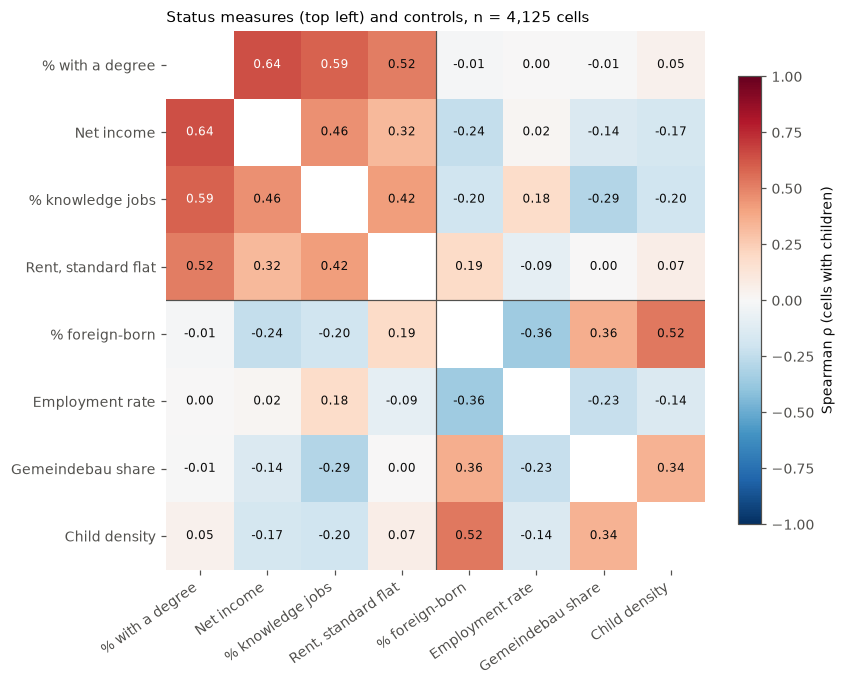

In [22]:
VARS = {**{c: v[0] for c, v in SES.items()}, "share_foreign_born_15_64": "% foreign-born", "emp_rate_15_64": "Employment rate",
        "gemeindebau_per_100_res": "Gemeindebau share", "child_density_km2": "Child density"}
cells = grid.loc[kid & grid[list(VARS)].notna().all(axis=1)]
corr = cells[list(VARS)].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.8, 6.6))
im = ax.imshow(np.where(np.eye(len(VARS)), np.nan, corr), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(VARS)), VARS.values(), rotation=35, ha="right"); ax.set_yticks(range(len(VARS)), VARS.values())
for (r, c), v in np.ndenumerate(corr.values):
    if r != c:
        ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if abs(v) > .55 else INK)
ax.axhline(3.5, color=INK2, lw=.8); ax.axvline(3.5, color=INK2, lw=.8)
ax.spines[:].set_visible(False)
fig.colorbar(im, ax=ax, shrink=.75, label="Spearman ρ (cells with children)")
ax.set_title(f"Status measures (top left) and controls, n = {len(cells):,} cells", fontsize=10, loc="left")
fig.tight_layout(); fig.savefig(FIG / "05_correlations.png", bbox_inches="tight"); plt.show()

### 4b. Status terciles: where are low-, middle- and high-status areas?
Each measure splits children into three equal groups (child-weighted terciles), the same grouping the analysis uses for its equity-gradient figure (Pennerstorfer used high / middle / low status thirds). The maps show which cells fall in each tercile. Where the four maps agree, the status ranking is robust to how status is measured.

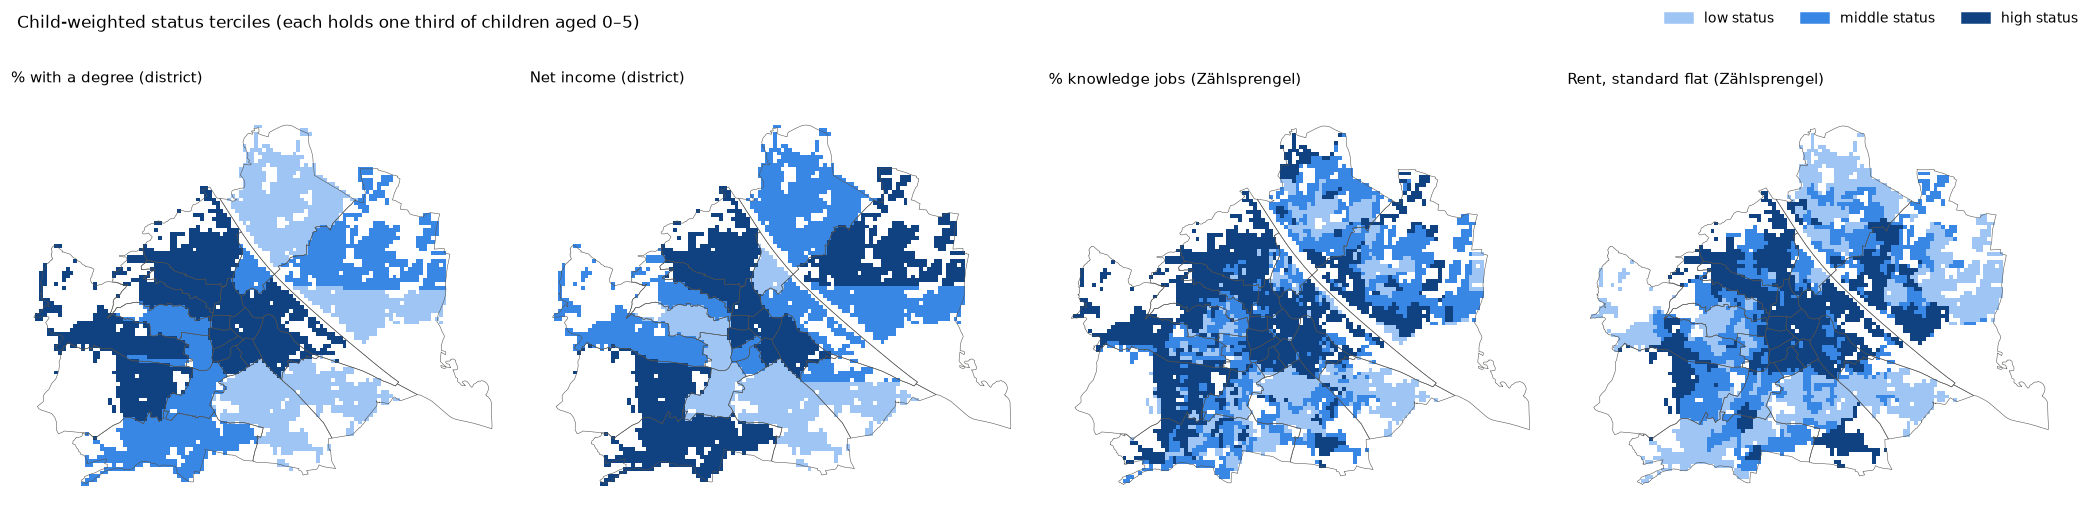

children in cells that all four measures put in the same tercile: 21%


In [23]:
for col in SES:
    grid[col + "_t3"] = pd.Series(pd.NA, index=grid.index, dtype="object")
    m = kid & grid[col].notna()
    grid.loc[m, col + "_t3"] = wtercile(grid.loc[m, col], grid.loc[m, "children_u6"])

t3_cmap = ListedColormap(list(TERCILE_COLOURS.values()))
fig, axes = plt.subplots(1, 4, figsize=(19, 5.2))
for ax, (col, (lab, lvl, _)) in zip(axes, SES.items()):
    g = grid[grid[col + "_t3"].notna()].copy()
    g["t"] = g[col + "_t3"].map({"low": 0, "middle": 1, "high": 2})
    g.plot("t", ax=ax, cmap=t3_cmap, vmin=-.5, vmax=2.5, edgecolor="none")
    districts.boundary.plot(ax=ax, color=INK2, lw=.35); ax.set_axis_off()
    ax.set_title(f"{lab} ({lvl})", fontsize=10, loc="left")
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in TERCILE_COLOURS.values()],
           labels=[f"{t} status" for t in TERCILE_COLOURS], loc="upper right", ncol=3, fontsize=9, frameon=False)
fig.suptitle("Child-weighted status terciles (each holds one third of children aged 0–5)", fontsize=11, x=.01, ha="left")
fig.tight_layout(); fig.savefig(FIG / "06_tercile_maps.png", bbox_inches="tight"); plt.show()

agree = grid.loc[kid & grid[[c + "_t3" for c in SES]].notna().all(axis=1), [c + "_t3" for c in SES] + ["children_u6"]]
same = agree[[c + "_t3" for c in SES]].nunique(axis=1).eq(1)
print(f"children in cells that all four measures put in the same tercile: {agree.loc[same, 'children_u6'].sum() / agree['children_u6'].sum():.0%}")

### 4c. Status terciles: who lives in them?
For each status measure (panel), the child-weighted average of the other variables in each tercile, as z-scores (0 = the average child; ±1 = one standard deviation). Read along a row: if low, middle and high status sit far apart, that variable differs systematically by status and must be controlled for. Large gaps on **child density** in particular mean that a raw status–access comparison would partly be a centre–periphery comparison.

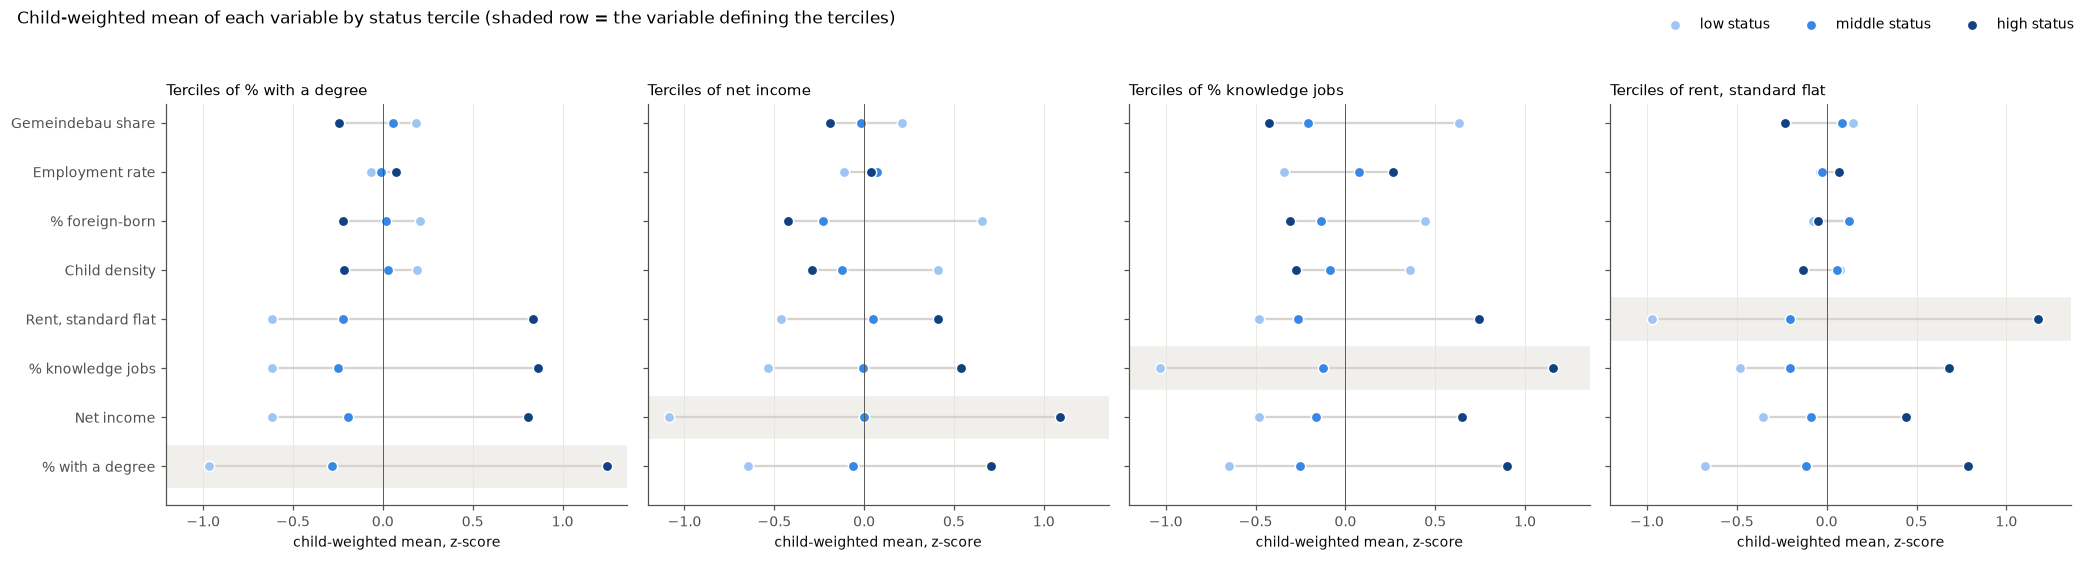

In [24]:
PROFILE = {**{c: v[0] for c, v in SES.items()}, "child_density_km2": "Child density",
           "share_foreign_born_15_64": "% foreign-born", "emp_rate_15_64": "Employment rate",
           "gemeindebau_per_100_res": "Gemeindebau share"}
base = grid.loc[kid & grid[list(PROFILE)].notna().all(axis=1)].copy()
for c in PROFILE:
    base[c + "_z"] = wz(base[c], base["children_u6"])

fig, axes = plt.subplots(1, 4, figsize=(19, 4.8), sharex=True, sharey=True)
rows = list(PROFILE)
for ax, (col, (lab, lvl, _)) in zip(axes, SES.items()):
    prof = base.groupby(col + "_t3").apply(lambda g: pd.Series({c: np.average(g[c + "_z"], weights=g["children_u6"]) for c in rows}),
                                           include_groups=False).reindex(["low", "middle", "high"])
    for i, c in enumerate(rows):
        ax.plot(prof[c], [i] * 3, color="#d5d4cf", lw=1.5, zorder=1)
    for t, colr in TERCILE_COLOURS.items():
        ax.scatter(prof.loc[t], range(len(rows)), s=46, color=colr, edgecolor="white", lw=1, zorder=2, label=f"{t} status")
    ax.axvline(0, color=INK2, lw=.6)
    ax.axhspan(rows.index(col) - .42, rows.index(col) + .42, color="#f0efec", zorder=0)   # the grouping variable itself
    ax.set_yticks(range(len(rows)), [PROFILE[c] for c in rows])
    ax.invert_yaxis(); ax.set_title(f"Terciles of {lab.lower()}", fontsize=10, loc="left")
    ax.set_xlabel("child-weighted mean, z-score"); ax.grid(axis="x", color="#e6e5e0", lw=.6); ax.set_axisbelow(True)
h_, l_ = axes[0].get_legend_handles_labels()
fig.legend(h_, l_, loc="upper right", ncol=3, fontsize=9, frameon=False, bbox_to_anchor=(1, 1.06))
fig.suptitle("Child-weighted mean of each variable by status tercile (shaded row = the variable defining the terciles)",
             fontsize=11, x=.01, ha="left", y=1.05)
fig.tight_layout(); fig.savefig(FIG / "07_tercile_profiles.png", bbox_inches="tight"); plt.show()

## 5. Coverage check and save
**Who drops out of the analysis?** The analysis notebook keeps cells with children where every status measure and control is present. The table counts, per variable, the children in cells where it is missing, and why. About 550 of 111,600 children (0.5%) are lost here, mostly in edge cells and withheld Zählsprengel. The analysis notebook loses a further ~320 where an access measure is undefined (e.g. reliability loss when access is zero), for a final sample of 110,764 children.

In [25]:
need = {"pct_tertiary": "district value", "net_income_eur": "district value", "share_knowledge_JKM": "no Zählsprengel, or withheld",
        "rent_eur_m2_std": "no Zählsprengel", "share_foreign_born_15_64": "Zählbezirk value",
        "emp_rate_15_64": "no Zählsprengel, or withheld", "gemeindebau_per_100_res": "Zählbezirk value"}
tot = grid.loc[kid, "children_u6"].sum()
cov = pd.DataFrame({c: {"cells with children missing it": int((kid & grid[c].isna()).sum()),
                        "children affected": grid.loc[kid & grid[c].isna(), "children_u6"].sum().round(0),
                        "reason if missing": why} for c, why in need.items()}).T
display(cov)
complete = kid & grid[list(need)].notna().all(axis=1)
print(f"children 0–5 in the routed grid: {tot:,.0f}; in cells with every variable: {grid.loc[complete, 'children_u6'].sum():,.0f} "
      f"({grid.loc[complete, 'children_u6'].sum() / tot:.1%}); lost: {tot - grid.loc[complete, 'children_u6'].sum():,.0f}, "
      f"of which in edge cells without a Zählsprengel: {grid.loc[kid & grid['zsp_id'].isna(), 'children_u6'].sum():,.0f}")

,cells with children missing it,children affected,reason if missing
pct_tertiary,0,0.0,district value
net_income_eur,0,0.0,district value
share_knowledge_JKM,170,527.0,"no Zählsprengel, or withheld"
rent_eur_m2_std,113,159.0,no Zählsprengel
share_foreign_born_15_64,0,0.0,Zählbezirk value
emp_rate_15_64,173,551.0,"no Zählsprengel, or withheld"
gemeindebau_per_100_res,0,0.0,Zählbezirk value


children 0–5 in the routed grid: 111,638; in cells with every variable: 111,087 (99.5%); lost: 551, of which in edge cells without a Zählsprengel: 159


**Save.**
`grid250_analysis.gpkg` (one row per 250 m cell, in routing order) is the input of `accessibility_analysis.ipynb`. `zaehlbezirke_analysis.gpkg/.csv` holds Zählbezirk totals and child-weighted means, for maps. `data_dictionary.csv` documents every column.

In [26]:
keep = ["gid", "cellcode", "origin_id", "north", "east", "SUB_DISTRICT_CODE", "DISTRICT_CODE", "zsp_id",
        "pop_official", "children_u6", "children_u3", "children_3_5", "child_density_km2",
        "pct_tertiary", "net_income_eur", "share_knowledge_JKM", "share_lowwage_IN", "rent_eur_m2_std",
        "share_foreign_born_15_64", "emp_rate_15_64", "gemeindebau_per_100_res", "gemeindebau_dwellings", "geometry"]
grid[keep].to_file(PROC / "grid250_analysis.gpkg", driver="GPKG")

def cw(g, c):
    m = g[c].notna() & (g["children_u6"] > 0)
    return np.average(g.loc[m, c], weights=g.loc[m, "children_u6"]) if m.any() else np.nan

zagg = grid.groupby("SUB_DISTRICT_CODE").apply(lambda g: pd.Series(
    {"children_u6": g["children_u6"].sum(), "children_u3": g["children_u3"].sum(), "pop_official": g["pop_official"].sum(),
     **{f"cw_{c}": cw(g, c) for c in ["share_knowledge_JKM", "rent_eur_m2_std", "emp_rate_15_64"]}}), include_groups=False)
zz = zbz.join(zbz_ctrl, on="SUB_DISTRICT_CODE").join(zagg, on="SUB_DISTRICT_CODE").join(bez, on="DISTRICT_CODE")
zz.to_file(PROC / "zaehlbezirke_analysis.gpkg", driver="GPKG")
zz.drop(columns="geometry").to_csv(PROC / "zaehlbezirke_analysis.csv", index=False)

dictionary = pd.DataFrame([
    ("gid, cellcode, origin_id, north, east", "Cell ids and lower-left corner (EPSG:3035); row order = travel-time matrices", "routing_origins.csv", "cell"),
    ("SUB_DISTRICT_CODE, DISTRICT_CODE, zsp_id", "Zählbezirk, district and Zählsprengel containing the cell centre", "boundaries", "cell"),
    ("pop_official", "Official residents", "Statistik Austria 100 m grid, 1 Jan 2026 → 250 m by area share", "cell"),
    ("children_u6", "Children aged 0–5 (0–4 + ⅕ of 5–9)", "Statistik Austria Zählsprengel ages, 1 Jan 2026 → 100 m residents (dasymetric) → 250 m (area share)", "cell"),
    ("children_u3, children_3_5", "Split of children_u6", "children_u6 × Zählbezirk births-based under-3 share", "cell"),
    ("child_density_km2", "children_u6 per km²", "derived", "cell"),
    ("pct_tertiary", "% of 25–64 with a tertiary degree", f"MA 23, {edu_year}", "district → cell"),
    ("net_income_eur", "Average annual net income of employees", f"MA 23, {inc_year}", "district → cell"),
    ("share_knowledge_JKM", "% of employed residents working in NACE J, K, M", "Statistik Austria employment register, 31 Oct 2024", "Zählsprengel → cell"),
    ("share_lowwage_IN", "% of employed residents working in NACE I, N", "same", "Zählsprengel → cell"),
    ("rent_eur_m2_std", "Asking rent € per m² per month, standard 65 m² flat", "willhaben 16 Nov 2026; build_rent_index.py", "Zählsprengel centre → cell"),
    ("share_foreign_born_15_64", "% of residents 15–64 born abroad", f"MA 23, 1 Jan {POP_YEAR}", "Zählbezirk → cell"),
    ("emp_rate_15_64", "Employed residents per 100 residents 15–64 (approx.)", "Statistik Austria employment register + ages", "Zählsprengel → cell"),
    ("gemeindebau_per_100_res", "Municipal-housing dwellings per 100 residents", "Wiener Wohnen estates (OGD) + MA 23 residents", "Zählbezirk → cell"),
    ("gemeindebau_dwellings", "Municipal-housing dwellings in the cell (estate placed at an interior point)", "Wiener Wohnen estates (OGD)", "cell"),
], columns=["variable", "meaning", "source", "level"])
dictionary.to_csv(PROC / "data_dictionary.csv", index=False)
print(f"saved grid {grid[keep].shape}, Zählbezirke {zz.shape}")
dictionary

saved grid (6950, 23), Zählbezirke (250, 16)


,variable,meaning,source,level
0,"gid, cellcode, origin_id, north, east",Cell ids and lower-left corner (EPSG:3035); ro...,routing_origins.csv,cell
1,"SUB_DISTRICT_CODE, DISTRICT_CODE, zsp_id","Zählbezirk, district and Zählsprengel containi...",boundaries,cell
2,pop_official,Official residents,"Statistik Austria 100 m grid, 1 Jan 2026 → 250...",cell
3,children_u6,Children aged 0–5 (0–4 + ⅕ of 5–9),"Statistik Austria Zählsprengel ages, 1 Jan 202...",cell
4,"children_u3, children_3_5",Split of children_u6,children_u6 × Zählbezirk births-based under-3 ...,cell
5,child_density_km2,children_u6 per km²,derived,cell
6,pct_tertiary,% of 25–64 with a tertiary degree,"MA 23, 2023",district → cell
7,net_income_eur,Average annual net income of employees,"MA 23, 2023",district → cell
8,share_knowledge_JKM,"% of employed residents working in NACE J, K, M","Statistik Austria employment register, 31 Oct ...",Zählsprengel → cell
9,share_lowwage_IN,"% of employed residents working in NACE I, N",same,Zählsprengel → cell
